# Detection : ou sont les defauts, et de quel type ?

Quatre moteurs derriere le meme contrat : YOLO11 (Ultralytics), YOLOX (Megvii), Faster R-CNN
(torchvision) et RF-DETR (Roboflow, transformer sans NMS). Le decoupage, le format pivot des annotations, l'evaluateur COCO et la carte du
modele sont communs, donc les quatre se comparent sur les memes images. Ce notebook deroule la
chaine avec YOLO11n sur un sous-ensemble de NEU-DET (essai court sur CPU), puis montre ce que
l'export garantit : la chaine ONNX + post-traitement ecrit en clair rend les memes boites.

In [1]:
import json  # json : affiche joliment une partie de la carte du modele
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : trace les figures
import pandas as pd  # pandas : tableaux de donnees (comptages, mesures par classe)
from IPython.display import Image, display  # affiche dans le notebook une image PNG deja enregistree sur disque

from vtb.annotate.draw import draw_annotation  # dessine les boites d'une annotation sur une copie de l'image
from vtb.core.config import load_config  # lit le fichier YAML de l'experience et verifie chaque reglage
from vtb.core.experiment import start  # prepare l'experience : dossier de sortie, journal, graines, choix CPU / GPU
from vtb.io.images import read_image  # lit une image en tableau numpy (couleur ou niveaux de gris)
from vtb.tasks.detection import workflow  # les etapes de la recette detection (prepare, train, evaluate, predict, export)
from vtb.tasks.detection.common import annotations_for  # relit les annotations (format pivot) d'une partie du decoupage
from vtb.tasks.detection.config import DetectionConfig  # le modele de configuration : la liste des cles autorisees dans le YAML

config = load_config("recipes/detection/configs/quick_yolo.yaml", DetectionConfig)  # config d'essai rapide avec YOLO11n
# meme config, mais les sorties vont dans un dossier a part pour ne pas melanger avec les experiences des scripts
config = config.model_copy(update={"runtime": config.runtime.model_copy(update={"output_dir": "outputs/detection/notebook"})})
output, device = start(config, "notebook")  # cree le dossier de sortie, le journal, fixe les graines ; device = CPU ou GPU

2026-11-05 20:36:14,233 | INFO | notebook | sortie outputs/detection/notebook | device cpu


## 1. Les annotations : un format pivot pour tous les formats d'origine

`prepare` lit les annotations (ici Pascal VOC ; aussi YOLO, COCO, LabelMe, Label Studio, CVAT
ou des masques), les convertit au format pivot de `vtb.annotate`, decoupe PAR IMAGE
(stratifie sur la classe principale) et ecrit `split.csv` + `split.vtb.json`.

In [2]:
if not Path(config.split.file).exists():  # si le decoupage n'a pas encore ete fait
    workflow.prepare(config)  # annotations au format pivot + decoupage train / val / test
train, class_names = annotations_for(config.split.file, "train")  # annotations des images de train et noms des classes
print(len(train), "images d'entrainement ;", class_names)  # combien d'images, quelles classes
counts = pd.Series([label for a in train for label in a.object_labels()]).value_counts()  # nombre d'objets par classe
print(counts)  # affiche le comptage (verifie qu'aucune classe n'est quasi absente)

168 images d'entrainement ; ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
inclusion          105
crazing             75
patches             73
scratches           59
rolled-in_scale     52
pitted_surface      38
Name: count, dtype: int64


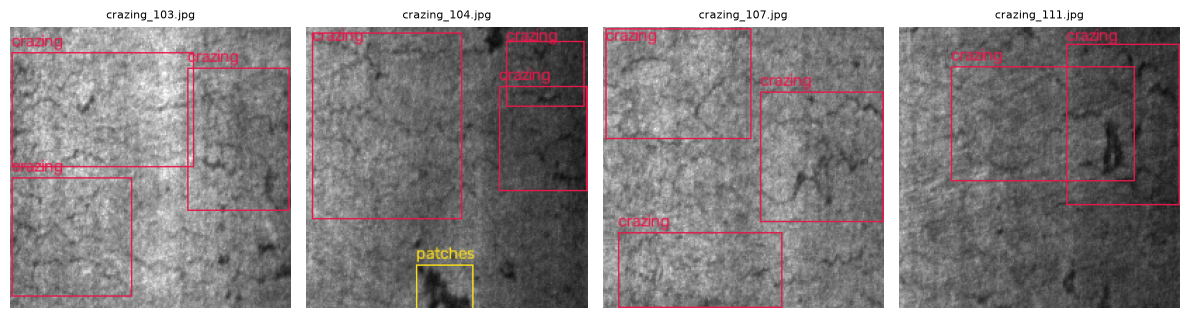

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))  # 4 cases cote a cote
for ax, ann in zip(axes, train[:4]):  # pour chaque case et chacune des 4 premieres images de train
    ax.imshow(draw_annotation(read_image(ann.image_path, color="gray"), ann, class_names, thickness=1))  # image + ses boites
    ax.set_title(Path(ann.image_path).name, fontsize=8)  # titre : nom du fichier
    ax.axis("off")  # masque les axes gradues
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure

## 2. Entrainer (2 epoques : verification de la chaine, pas precision)

Ultralytics fait lui-meme Dataset, augmentations (mosaic...) et boucle ; la toolbox ecrit le
jeu au format YOLO depuis le pivot, avec le meme pretraitement qu'en production.

In [4]:
info = workflow.train(config, output, device)  # entraine le detecteur ; renvoie ses infos (moteur, taille d'entree, duree...)
print({k: info[k] for k in ("backend", "input_size", "train_seconds")})  # affiche trois de ces infos

2026-11-05 20:36:48,695 | INFO | entrainement ultralytics : 34.1 s


2026-11-05 20:36:48,892 | INFO | entrainement ultralytics termine en 34 s -> outputs/detection/notebook/best.pt


{'backend': 'ultralytics', 'input_size': 320, 'train_seconds': 34.1}


## 3. Evaluer : mAP COCO (toute la courbe) ET point de fonctionnement (le seuil de production)

Le mAP resume la courbe precision-rappel ; l'operateur, lui, voit le seuil `conf_predict`.
On regarde donc aussi precision et rappel a ce seuil, par classe, et la decision par image.

2026-11-05 20:36:49,694 | INFO | prediction du test : 0.8 s


2026-11-05 20:36:50,608 | INFO | test (36 images) : mAP50 0.130 | mAP50-95 0.052 | au seuil 0.25 : precision 0.207 rappel 0.143


mAP50 0.13 | mAP50-95 0.052
                   ap50  ap50_95   tp    fp    fn  precision  recall
crazing          0.0285   0.0073  0.0   6.0  17.0     0.0000  0.0000
inclusion        0.1338   0.0424  1.0  10.0  23.0     0.0909  0.0417
patches          0.4469   0.2065  7.0  10.0  10.0     0.4118  0.4118
pitted_surface   0.0118   0.0056  0.0   1.0   5.0     0.0000  0.0000
rolled-in_scale  0.0000   0.0000  0.0   0.0  12.0     0.0000  0.0000
scratches        0.1607   0.0499  4.0  19.0   5.0     0.1739  0.4444


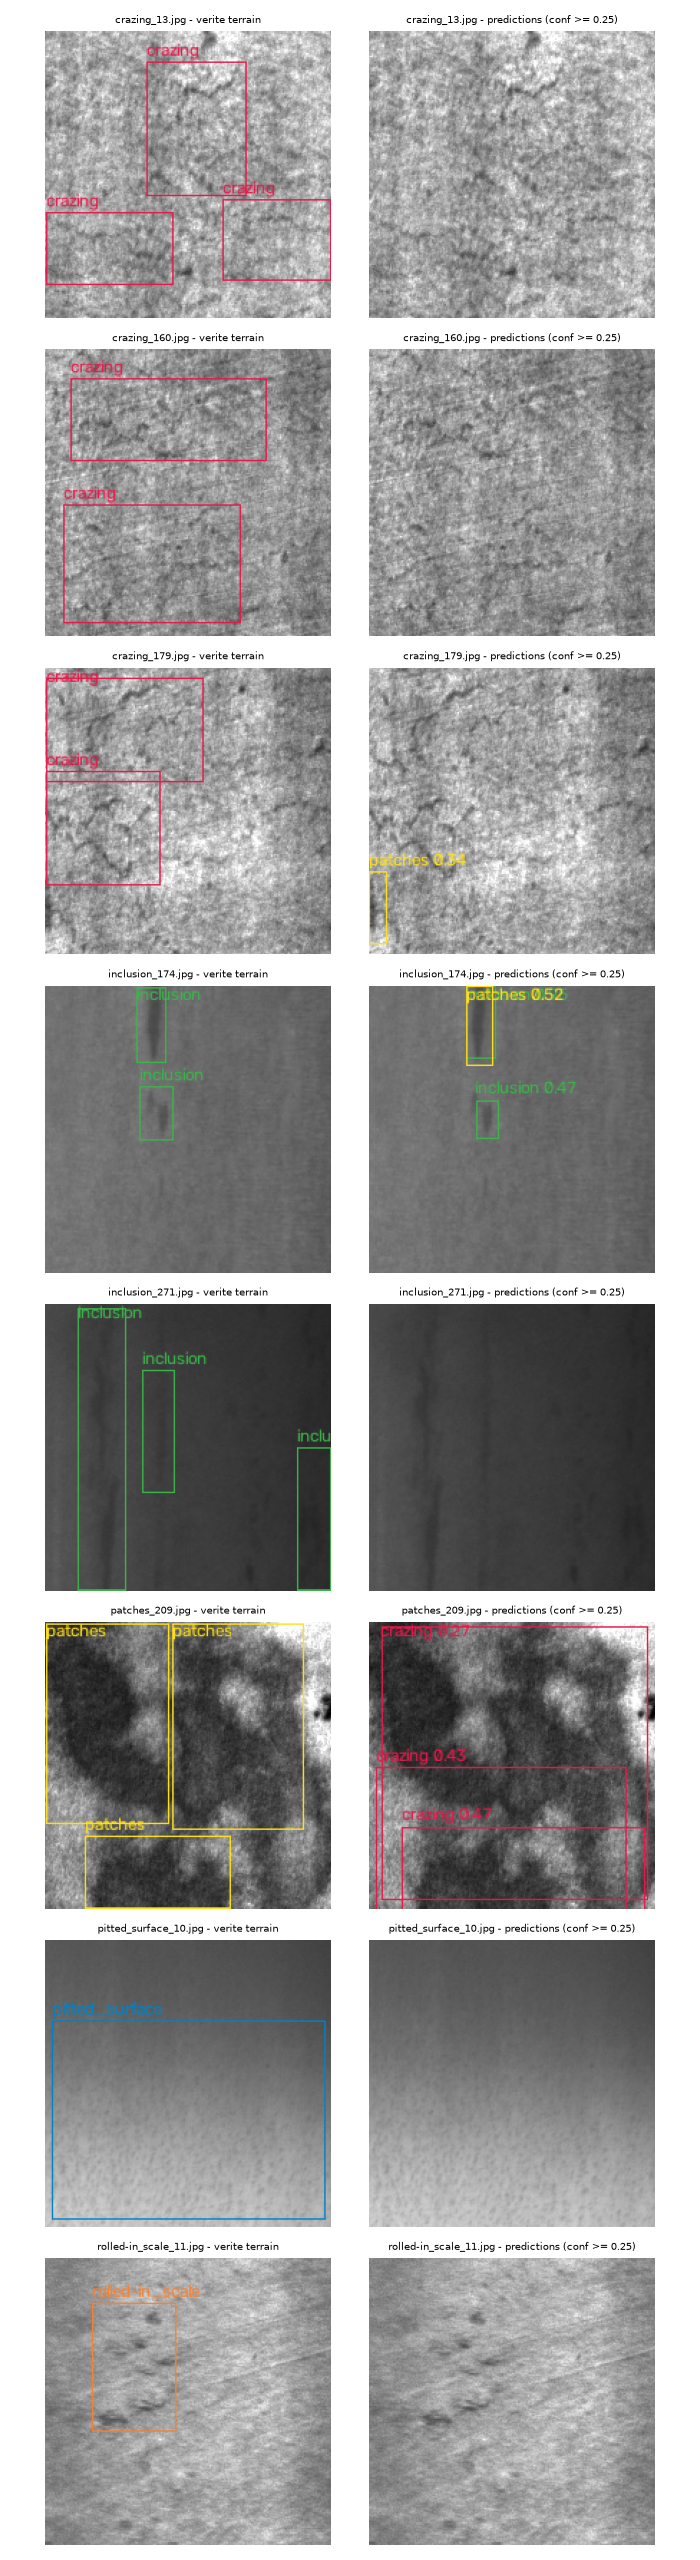

In [5]:
metrics = workflow.evaluate(config, output, device)  # mesures sur le jeu de test
# mAP50 : precision moyenne avec une boite jugee juste si IoU (recouvrement) >= 0,5 ; mAP50-95 : moyenne sur IoU 0,5 a 0,95
print("mAP50", round(metrics["map50"], 3), "| mAP50-95", round(metrics["map50_95"], 3))
print(pd.read_csv(output / "per_class.csv", index_col=0))  # detail par classe (index_col=0 : 1re colonne = nom de ligne)
display(Image(str(output / "test_predictions.png"), width=520))  # galerie d'images de test avec les boites predites

## 4. Exporter et verifier

L'ONNX sort les predictions BRUTES (sans NMS). La verification compare (1) ces sorties au
reseau PyTorch, (2) les boites obtenues par `postprocess_detect` (letterbox defait, NMS par
classe, ecrit en numpy) a celles de `model.predict` d'Ultralytics : IoU moyen attendu ~1.

In [6]:
card = workflow.export(config, output)  # export ONNX verifie ; renvoie la carte du modele (model_card.json)
print(card.notes)  # remarques ecrites pendant l'export (resultat des verifications...)
print(json.dumps(card.input.model_dump(), indent=1))  # description de l'entree attendue par le modele (taille, couleur...)

WARNING ⚠️ This model has no one-to-one head; using one-to-many outputs.


2026-11-05 20:36:51,942 | INFO | verification ONNX Ultralytics : {'raw_max_abs_diff': 0.001953125, 'raw_scale': 483.2890625, 'boxes': 27, 'reference_boxes': 27, 'mean_iou': 0.9999991787804497}


2026-11-05 20:36:53,081 | INFO | OpenVINO ecrit : outputs/detection/notebook/model.xml


2026-11-05 20:36:55,377 | INFO | latence : {'torch_cpu_ms': 114.41, 'batch': 1, 'onnxruntime_cpu_ms': 35.83, 'openvino_cpu_ms': 10.17}


verification ONNX : {'raw_max_abs_diff': 0.001953125, 'raw_scale': 483.2890625, 'boxes': 27, 'reference_boxes': 27, 'mean_iou': 0.9999991787804497}
{
 "name": "images",
 "layout": "NCHW",
 "height": 320,
 "width": 320,
 "channels": 3,
 "color": "RGB",
 "dtype": "float32",
 "scale": "divide by 255",
 "mean": [],
 "std": [],
 "resize": "letterbox",
 "letterbox_pad_value": 114,
 "dynamic_batch": true,
 "read_color": "gray"
}


## 5. Comparer les moteurs

Lancer les essais rapides (`quick_yolo`, `quick_yolox`, `quick_fasterrcnn`, `quick_rfdetr`) puis
`compare.py` : memes images, meme evaluateur. Les vrais chiffres viennent des configurations
completes, sur GPU.

In [7]:
comparison = Path("docs/assets/detection/quick_comparison.md")  # tableau comparatif ecrit par compare.py
print(  # affiche le tableau s'il existe
    # sinon : la commande a lancer pour le produire
    comparison.read_text() if comparison.exists() else "lancer : python recipes/detection/scripts/compare.py --markdown " + str(comparison)
)

| experience       | moteur      | modele                             | split                                  |   entree_px |   temps_s |   test_map50 |   test_map50_95 |   precision@conf |   rappel@conf |   onnx_ms |
|:-----------------|:------------|:-----------------------------------|:---------------------------------------|------------:|----------:|-------------:|----------------:|-----------------:|--------------:|----------:|
| notebook         | ultralytics | ultralytics:yolo11n                | outputs/detection/quick_split.csv      |         320 |      58.5 |        0.13  |           0.052 |           0.2069 |        0.1429 |     43.13 |
| quick_fasterrcnn | fasterrcnn  | fasterrcnn:fasterrcnn_resnet18_fpn | outputs/detection/quick_split.csv      |         224 |     560.7 |        0.068 |           0.032 |           0      |        0      |    342.54 |
| quick_obb_tile   | ultralytics | ultralytics:yolo11n-obb            | outputs/detection/quick_tile_split.csv |         256